QUESTION NO 1 PROMPT ; 
Write a complete Python program for the equilibrium reaction (A+B\rightleftharpoons C), where the initial concentrations are ([A]_0=0.5) mol/L, ([B]_0=0.5) mol/L, and ([C]_0=0). Read (K_c) from user input, print the raw input and its type, and show a clear error if the input is not a valid positive finite number. Derive and solve (K_c=x/(0.5-x)^2), displaying the quadratic coefficients (a,b,c), discriminant, and both roots to three decimal places. Select and explain the physically meaningful root in the range (0\le x\le0.5). Calculate the conversion of the limiting reactant as (x/0.5\times100%), print the equilibrium concentrations, and classify conversion as High if it is greater than 70%, Moderate if it is at least 40%, and Low otherwise. Include comments explaining the logic.”

In [15]:
#question number 1 equillibrium conversion checker


import math

raw_input_value = input("Enter the equilibrium constant Kc: ")

print(f"Raw input: {raw_input_value!r}")
print(f"Raw input type: {type(raw_input_value).__name__}")

try:
    kc = float(raw_input_value)
except ValueError:
    print("Error: Kc must be a number, such as 2 or 0.75.")
    raise SystemExit

print(f"Parsed Kc: {kc}")
print(f"Parsed Kc type: {type(kc).__name__}")

if not math.isfinite(kc) or kc <= 0:
    print("Error: Kc must be a finite number greater than zero.")
    raise SystemExit

# Coefficients for: a*x^2 + b*x + c = 0
a = kc
b = -(kc + 1)
c = 0.25 * kc

# This is equivalent to b**2 - 4*a*c, simplified for this equation.
discriminant = 2 * kc + 1

print("\nQuadratic equation:")
print("Kc*x^2 - (Kc + 1)*x + 0.25*Kc = 0")
print(f"a = {a:.3f}")
print(f"b = {b:.3f}")
print(f"c = {c:.3f}")
print(f"Discriminant = {discriminant:.3f}")

sqrt_discriminant = math.sqrt(discriminant)

# Calculate the larger root first, then use the product of the roots
# to calculate the smaller root more accurately.
larger_root = ((kc + 1) + sqrt_discriminant) / (2 * kc)
smaller_root = 0.25 / larger_root

print(f"\nRoot 1 (larger): {larger_root:.3f}")
print(f"Root 2 (smaller): {smaller_root:.3f}")

roots = [larger_root, smaller_root]
physical_roots = [root for root in roots if 0 <= root <= 0.5]

if not physical_roots:
    print("Error: No root is in the physical range from 0 to 0.5 mol/L.")
    raise SystemExit

x = physical_roots[0]

# A and B start at the same concentration and react in a 1:1 ratio.
# Therefore, either is a limiting reactant; use A for the conversion.
initial_a = 0.5
conversion_percent = (x / initial_a) * 100

print(f"\nPhysical root x: {x:.3f} mol/L")
print(f"Equilibrium [A]: {initial_a - x:.3f} mol/L")
print(f"Equilibrium [B]: {initial_a - x:.3f} mol/L")
print(f"Equilibrium [C]: {x:.3f} mol/L")
print(f"Limiting-reactant conversion: {conversion_percent:.3f}%")

if conversion_percent > 70:
    classification = "High"
elif conversion_percent >= 40:
    classification = "Moderate"
else:
    classification = "Low"

print(f"Conversion classification: {classification}")

Raw input: '0.5'
Raw input type: str
Parsed Kc: 0.5
Parsed Kc type: float

Quadratic equation:
Kc*x^2 - (Kc + 1)*x + 0.25*Kc = 0
a = 0.500
b = -1.500
c = 0.125
Discriminant = 2.000

Root 1 (larger): 2.914
Root 2 (smaller): 0.086

Physical root x: 0.086 mol/L
Equilibrium [A]: 0.414 mol/L
Equilibrium [B]: 0.414 mol/L
Equilibrium [C]: 0.086 mol/L
Limiting-reactant conversion: 17.157%
Conversion classification: Low


QUESTION NUMBER 2 ;
Part A: Batch Reactor Simulation
A first-order reaction takes place in a batch reactor with an initial concentration of 1.0 mol/L and a rate constant of 0.12 min⁻¹. Use Euler’s method with a time step of 0.5 minutes to model the reaction over the first five minutes. Display the concentration and percentage conversion at each step. Compare the concentration predicted by Euler’s method at five minutes with the exact first-order result, and calculate the absolute error. Then restart the simulation and determine whether the reactor reaches 70% conversion within 100 minutes. Report the final time, concentration, conversion, and whether the target was reached.
Part B: Lot-Code Digit Analysis
Storage-tank lot codes may contain letters, numbers, or both. Write a function that counts the digits in a lot code and calculates their sum. Test it with a code entered by the user, as well as examples that contain digits, are empty, and contain no digits. Display a suitable message for empty codes and codes with no digits.

In [16]:
# question number 2  BATCH REACTOR STIMULATION AND BATCH TRACKING
#part A

# Given data
c0 = 1.0       # Initial concentration, mol/L
k = 0.12       # Rate constant, min^-1
delta_t = 0.5  # Time step, min

# Part 1: Euler simulation for 5 minutes
concentration = c0
time = 0.0
number_of_steps = int(5 / delta_t)

print("Euler simulation for 5 minutes")
print(f"{'Time (min)':>12} {'Concentration (mol/L)':>24} {'Conversion (%)':>18}")

conversion = (c0 - concentration) / c0 * 100
print(f"{time:12.2f} {concentration:24.6f} {conversion:18.2f}")

for step in range(number_of_steps):
    # Euler method: C_new = C_old - k * C_old * delta_t
    concentration = concentration - k * concentration * delta_t
    time += delta_t

    conversion = (c0 - concentration) / c0 * 100
    print(f"{time:12.2f} {concentration:24.6f} {conversion:18.2f}")

euler_concentration = concentration
exact_concentration = c0 * math.exp(-k * 5)
absolute_error = abs(euler_concentration - exact_concentration)

print(f"\nEuler concentration at 5 min: {euler_concentration:.6f} mol/L")
print(f"Exact concentration at 5 min: {exact_concentration:.6f} mol/L")
print(f"Absolute error: {absolute_error:.6f} mol/L")

# Part 2: Continue until conversion reaches 70% or time reaches 100 minutes
concentration = c0
time = 0.0
conversion = 0.0

while conversion < 70 and time < 100:
    concentration = concentration - k * concentration * delta_t
    time += delta_t
    conversion = (c0 - concentration) / c0 * 100

print("\nSimulation until 70% conversion or 100 minutes")
print(f"Time reached: {time:.2f} min")
print(f"Final concentration: {concentration:.6f} mol/L")
print(f"Final conversion: {conversion:.2f}%")

if conversion >= 70:
    print("The 70% conversion target was reached.")
else:
    print("The 100-minute time limit was reached before 70% conversion.")

Euler simulation for 5 minutes
  Time (min)    Concentration (mol/L)     Conversion (%)
        0.00                 1.000000               0.00
        0.50                 0.940000               6.00
        1.00                 0.883600              11.64
        1.50                 0.830584              16.94
        2.00                 0.780749              21.93
        2.50                 0.733904              26.61
        3.00                 0.689870              31.01
        3.50                 0.648478              35.15
        4.00                 0.609569              39.04
        4.50                 0.572995              42.70
        5.00                 0.538615              46.14

Euler concentration at 5 min: 0.538615 mol/L
Exact concentration at 5 min: 0.548812 mol/L
Absolute error: 0.010197 mol/L

Simulation until 70% conversion or 100 minutes
Time reached: 10.00 min
Final concentration: 0.290106 mol/L
Final conversion: 70.99%
The 70% conversion target was 

In [22]:
# question number 2 ; part B LOT CODE DIGIT ANALYSIS
def analyze_lot_code(code):
    digit_count = 0
    digit_sum = 0

    for character in code:
        if character in "0123456789":
            digit_count += 1
            digit_sum += int(character)

    print(f"\nCode: {code!r}")
    print(f"Number of digits: {digit_count}")
    print(f"Sum of digits: {digit_sum}")

    if code == "":
        print("Message: The code is empty.")
    elif digit_count == 0:
        print("Message: The code contains no digits.")


lot_code = input("Enter a storage tank lot code: ")
analyze_lot_code(lot_code)

# Example tests
analyze_lot_code("TK00045-lot19")
analyze_lot_code("")
analyze_lot_code("abcdef")


Code: ' '
Number of digits: 0
Sum of digits: 0
Message: The code contains no digits.

Code: 'TK00045-lot19'
Number of digits: 7
Sum of digits: 19

Code: ''
Number of digits: 0
Sum of digits: 0
Message: The code is empty.

Code: 'abcdef'
Number of digits: 0
Sum of digits: 0
Message: The code contains no digits.


QUESTION NUMBER 3 ;

Write a Python program with two parts.

**Part A: Number of Possible Blends**  
Create a recursive function to calculate the factorial of a non-negative integer, then use it to calculate the number of ways to choose `r` ingredients from `n` ingredients using the combinations formula. Validate the inputs and display a clear error if they are invalid. Test the program with `n = 8, r = 4` and with `n = 3, r = 5`.

**Part B: Fibonacci Cooling-Time Reads**  
Generate the first eight Fibonacci numbers using both an iterative function and a recursive function, where the sequence starts with `1, 1`. Compare the two results and report whether they agree. Display a table with each read number, its Fibonacci value, and its cooling time in minutes, calculated as the Fibonacci value multiplied by 3. Include comments explaining the logic.1

In [23]:
# QUESTION:3 RECURSIVE COMBINATIONS AND FIBONACCI COOLING TIMES


# -------------------- PART A: NUMBER OF BLENDS --------------------

def factorial_recursive(number):
    """Return number! using recursion."""
    if type(number) is not int or number < 0:
        raise ValueError("Factorial input must be a non-negative integer.")

    # Base cases
    if number == 0 or number == 1:
        return 1

    # Recursive case
    return number * factorial_recursive(number - 1)


def combinations(n, r):
    """Calculate n choose r using recursive factorials."""
    if type(n) is not int or type(r) is not int:
        raise ValueError("n and r must both be integers.")

    if n < 0 or r < 0:
        raise ValueError("n and r cannot be negative.")

    if r > n:
        raise ValueError("r cannot be greater than n.")

    return factorial_recursive(n) // (
        factorial_recursive(r) * factorial_recursive(n - r)
    )


def print_blend_count(n, r):
    """Print the blend count or a clear invalid-input message."""
    try:
        count = combinations(n, r)
        print(f"For n = {n} and r = {r}, the number of possible blends is {count}.")
    except (ValueError, RecursionError) as error:
        print(f"Invalid input for n = {n}, r = {r}: {error}")


print("PART A: NUMBER OF POSSIBLE BLENDS")
print_blend_count(8, 4)
print_blend_count(3, 5)


# -------------------- PART B: FIBONACCI COOLING TIMES --------------------

def fib_iter(count):
    """Return the first count Fibonacci numbers iteratively."""
    if type(count) is not int or count < 0:
        raise ValueError("The number of Fibonacci terms must be a non-negative integer.")

    sequence = []
    first = 1
    second = 1

    for _ in range(count):
        sequence.append(first)
        first, second = second, first + second

    return sequence


def fib_recursive(index):
    """Return the Fibonacci value at index, with F0 = 1 and F1 = 1."""
    if type(index) is not int or index < 0:
        raise ValueError("The Fibonacci index must be a non-negative integer.")

    # Base cases
    if index == 0 or index == 1:
        return 1

    # Recursive case
    return fib_recursive(index - 1) + fib_recursive(index - 2)


number_of_reads = 8

iterative_values = fib_iter(number_of_reads)
recursive_values = [
    fib_recursive(index) for index in range(number_of_reads)
]

print("\nPART B: FIBONACCI COOLING-TIME READS")

if iterative_values == recursive_values:
    print("The iterative and recursive Fibonacci results agree.")
else:
    print("Error: The Fibonacci results do not agree.")

print(f"{'Read':>6} {'Fibonacci value':>18} {'Time (min)':>14}")

for read_number, fibonacci_value in enumerate(iterative_values, start=1):
    time_minutes = fibonacci_value * 3
    print(f"{read_number:6} {fibonacci_value:18} {time_minutes:14}")

PART A: NUMBER OF POSSIBLE BLENDS
For n = 8 and r = 4, the number of possible blends is 70.
Invalid input for n = 3, r = 5: r cannot be greater than n.

PART B: FIBONACCI COOLING-TIME READS
The iterative and recursive Fibonacci results agree.
  Read    Fibonacci value     Time (min)
     1                  1              3
     2                  1              3
     3                  2              6
     4                  3              9
     5                  5             15
     6                  8             24
     7                 13             39
     8                 21             63


QUESTION NUMBER 4 ;
Part A: Reaction Data**

Make a pandas DataFrame using the time and concentration data for the two UV runs. Save the data as a CSV file and a JSON file. Read the CSV file back in and print the data, its shape, and the column types.

Find the mean and standard deviation for each run. Say which run has more variation, then plot both runs on the same graph with a title, axis labels, a legend, and a grid.

**Part B: Pressure and Volume**

Make a DataFrame using the volume and pressure values. Calculate $PV$ for each row and find the average $PV$ value. Print the table and the average.

Plot the measured data and add a reference curve using $P = k/V$, where $k$ is the average $PV$. Add a title, axis labels, a legend, and a grid.

Data read from CSV:
   Time_min  Run1_Low_UV_mol_L  Run2_High_UV_mol_L
0         0               0.80                0.80
1        10               0.54                0.44
2        20               0.36                0.24
3        30               0.24                0.13
4        40               0.16                0.07
5        50               0.11                0.04

Shape:
(6, 3)

Data types:
Time_min                int64
Run1_Low_UV_mol_L     float64
Run2_High_UV_mol_L    float64
dtype: object

Concentration statistics (mol/L):
Run 1, low UV:  mean = 0.368333, standard deviation = 0.261719
Run 2, high UV: mean = 0.286667, standard deviation = 0.290356
Run 2 shows more deviation.


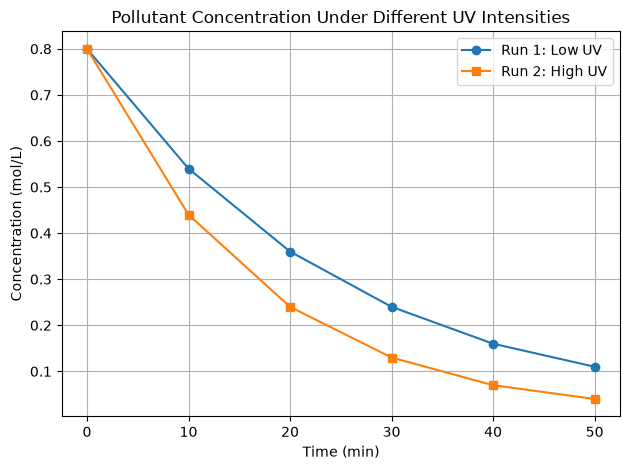

In [24]:
# question number 4 a 
import pandas as pd
import matplotlib.pyplot as plt

# Build a DataFrame from the concentration table
kinetics = pd.DataFrame({
    "Time_min": [0, 10, 20, 30, 40, 50],
    "Run1_Low_UV_mol_L": [0.80, 0.54, 0.36, 0.24, 0.16, 0.11],
    "Run2_High_UV_mol_L": [0.80, 0.44, 0.24, 0.13, 0.07, 0.04]
})

# Save the data in both formats
kinetics.to_csv("kinetic.csv", index=False)
kinetics.to_json("kinetic.json", orient="records", indent=2)

# Read the CSV back and inspect it
data = pd.read_csv("kinetic.csv")
print("Data read from CSV:")
print(data)
print("\nShape:")
print(data.shape)
print("\nData types:")
print(data.dtypes)

# Calculate mean and sample standard deviation for each run
run1_mean = data["Run1_Low_UV_mol_L"].mean()
run1_std = data["Run1_Low_UV_mol_L"].std()

run2_mean = data["Run2_High_UV_mol_L"].mean()
run2_std = data["Run2_High_UV_mol_L"].std()

print("\nConcentration statistics (mol/L):")
print(f"Run 1, low UV:  mean = {run1_mean:.6f}, standard deviation = {run1_std:.6f}")
print(f"Run 2, high UV: mean = {run2_mean:.6f}, standard deviation = {run2_std:.6f}")

if run1_std > run2_std:
    print("Run 1 shows more deviation.")
elif run2_std > run1_std:
    print("Run 2 shows more deviation.")
else:
    print("Both runs have the same standard deviation.")

# Plot both runs on the same graph
plt.plot(
    data["Time_min"], data["Run1_Low_UV_mol_L"],
    marker="o", label="Run 1: Low UV"
)
plt.plot(
    data["Time_min"], data["Run2_High_UV_mol_L"],
    marker="s", label="Run 2: High UV"
)

plt.title("Pollutant Concentration Under Different UV Intensities")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("kinetic_plot.png", dpi=300)
plt.show()

Pressure-volume data:
   Volume_L  Pressure_bar  PV_bar_L
0         2          3.01      6.02
1         3          1.98      5.94
2         4          1.52      6.08
3         5          1.19      5.95
4         6          1.01      6.06

Mean k (mean PV): 6.010 bar·L


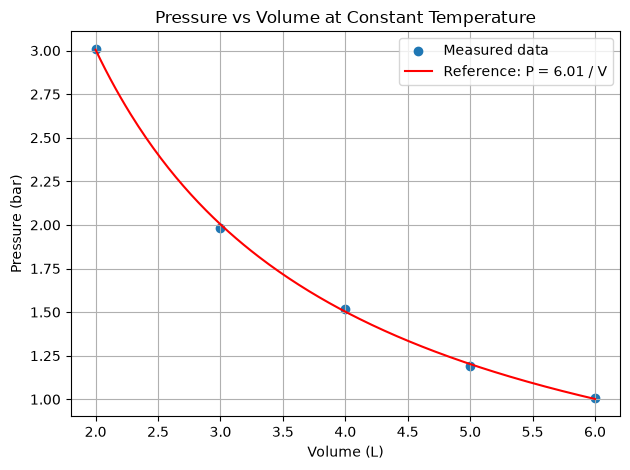

In [26]:
# question number 4 b
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Enter the measured volume and pressure data
gas_data = pd.DataFrame({
    "Volume_L": [2, 3, 4, 5, 6],
    "Pressure_bar": [3.01, 1.98, 1.52, 1.19, 1.01]
})

# Calculate PV for each measurement, then find the mean value of k
gas_data["PV_bar_L"] = gas_data["Volume_L"] * gas_data["Pressure_bar"]
k = gas_data["PV_bar_L"].mean()

print("Pressure-volume data:")
print(gas_data)
print(f"\nMean k (mean PV): {k:.3f} bar·L")

# Plot the measured points and reference curve P = k / V
volume_curve = np.linspace(
    gas_data["Volume_L"].min(),
    gas_data["Volume_L"].max(),
    200
)
pressure_reference = k / volume_curve

plt.scatter(
    gas_data["Volume_L"], gas_data["Pressure_bar"],
    label="Measured data"
)
plt.plot(
    volume_curve, pressure_reference,
    color="red", label=f"Reference: P = {k:.2f} / V"
)

plt.title("Pressure vs Volume at Constant Temperature")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("kinetics_json.png", dpi=300)
plt.show()